# Dimensionality Reduction & Unsupervised Clustering

**Goal:** discover structure in high-dimensional data using PCA and three clustering families
(K-Means, Hierarchical, DBSCAN).

**Dataset:** Wisconsin Breast Cancer diagnostic data (569 samples x 30 numeric features) from scikit-learn.
The diagnosis label (benign / malignant) is **never** used for fitting. It is only used at the end as an
external sanity check on how well the unsupervised clusters recover real structure.

**Pipeline**
1. Load and standardize features
2. PCA, scree plot and cumulative explained variance, choose number of components
3. K-Means, Elbow method + Silhouette analysis to choose *k*
4. 2D / 3D cluster visualization (Seaborn + Plotly)
5. Hierarchical clustering (dendrogram) and DBSCAN
6. Side-by-side comparison and conclusions

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             adjusted_rand_score, davies_bouldin_score,
                             calinski_harabasz_score)
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

## 1. Load and standardize the data

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y_true = data.target.map({0: "malignant", 1: "benign"})   # held out, used ONLY for evaluation

print(f"Shape: {X.shape[0]} samples x {X.shape[1]} features")
print("Missing values:", int(X.isna().sum().sum()))
X.describe().T[["mean", "std", "min", "max"]].head(8)

Shape: 569 samples x 30 features
Missing values: 0


,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.1100
mean texture,19.289649,4.301036,9.71000,39.2800
mean perimeter,91.969033,24.298981,43.79000,188.5000
mean area,654.889104,351.914129,143.50000,2501.0000
mean smoothness,0.096360,0.014064,0.05263,0.1634
mean compactness,0.104341,0.052813,0.01938,0.3454
mean concavity,0.088799,0.079720,0.00000,0.4268
mean concave points,0.048919,0.038803,0.00000,0.2012


Feature scales differ by orders of magnitude (e.g. `mean area` is in the hundreds, `mean smoothness` is
about 0.1). PCA and K-Means are variance / distance based, so unscaled features with large ranges would
dominate. We standardize every feature to zero mean and unit variance.

Post-scaling mean (max abs): 0.0
Post-scaling std  (min/max): 1.0 / 1.0


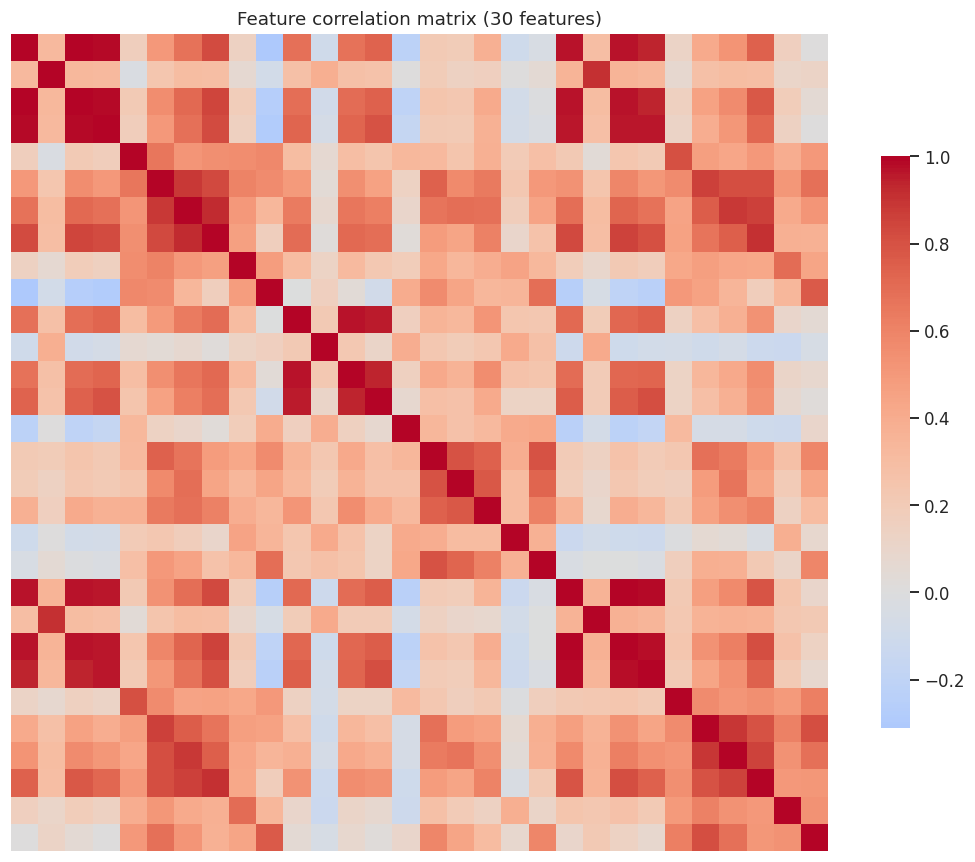

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Post-scaling mean (max abs):", np.abs(X_scaled.mean(axis=0)).max().round(6))
print("Post-scaling std  (min/max):", X_scaled.std(axis=0).min().round(3), "/", X_scaled.std(axis=0).max().round(3))

# Many features are strongly correlated, which is exactly why PCA should compress well
corr = pd.DataFrame(X_scaled, columns=X.columns).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7},
            xticklabels=False, yticklabels=False)
plt.title("Feature correlation matrix (30 features)")
plt.tight_layout(); plt.show()

## 2. Principal Component Analysis and scree plot

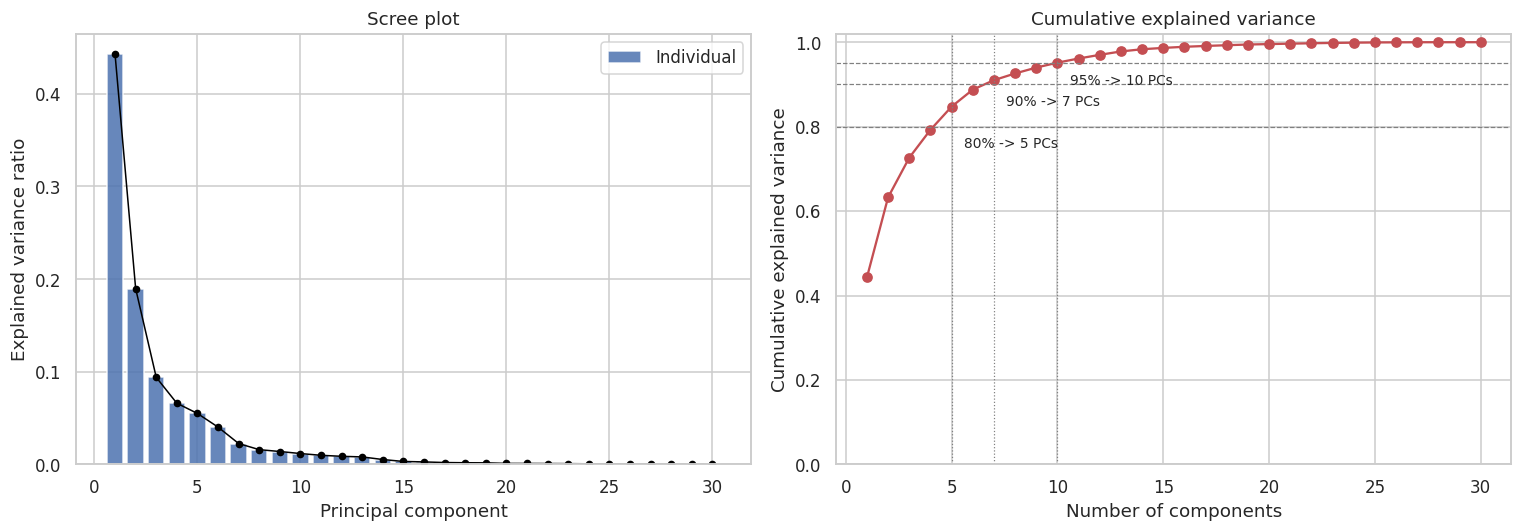

In [4]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n = len(evr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
ax = axes[0]
ax.bar(range(1, n + 1), evr, color=sns.color_palette("deep")[0], alpha=.85, label="Individual")
ax.plot(range(1, n + 1), evr, "o-", color="black", ms=4, lw=1)
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio")
ax.set_title("Scree plot"); ax.legend()

# Cumulative
ax = axes[1]
ax.plot(range(1, n + 1), cum, "o-", color=sns.color_palette("deep")[3])
for thr in (0.80, 0.90, 0.95):
    k = int(np.argmax(cum >= thr)) + 1
    ax.axhline(thr, ls="--", c="grey", lw=.8)
    ax.axvline(k, ls=":", c="grey", lw=.8)
    ax.annotate(f"{int(thr*100)}% -> {k} PCs", (k, thr), textcoords="offset points",
                xytext=(8, -14), fontsize=9)
ax.set_xlabel("Number of components"); ax.set_ylabel("Cumulative explained variance")
ax.set_title("Cumulative explained variance"); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

### Choosing the number of components
We combine three standard criteria rather than relying on one:
- **Cumulative variance threshold** (e.g. >= 95%)
- **Kaiser criterion**: keep components with eigenvalue > 1 (i.e. they explain more variance than one original standardized feature)
- **Scree elbow**: where the individual bars flatten out

In [5]:
eigvals = pca_full.explained_variance_
k_kaiser = int((eigvals > 1).sum())
k_80  = int(np.argmax(cum >= 0.80)) + 1
k_90  = int(np.argmax(cum >= 0.90)) + 1
k_95  = int(np.argmax(cum >= 0.95)) + 1

summary = pd.DataFrame({
    "Criterion": ["Kaiser (eigenvalue > 1)", ">= 80% variance", ">= 90% variance", ">= 95% variance"],
    "Components": [k_kaiser, k_80, k_90, k_95],
})
display(summary)

N_COMPONENTS = k_95
print(f"\nChosen: {N_COMPONENTS} components retain {cum[N_COMPONENTS-1]:.1%} of the variance "
      f"(30 -> {N_COMPONENTS} dimensions).")

pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
pc_cols = [f"PC{i+1}" for i in range(N_COMPONENTS)]

,Criterion,Components
0,Kaiser (eigenvalue > 1),6
1,>= 80% variance,5
2,>= 90% variance,7
3,>= 95% variance,10



Chosen: 10 components retain 95.2% of the variance (30 -> 10 dimensions).


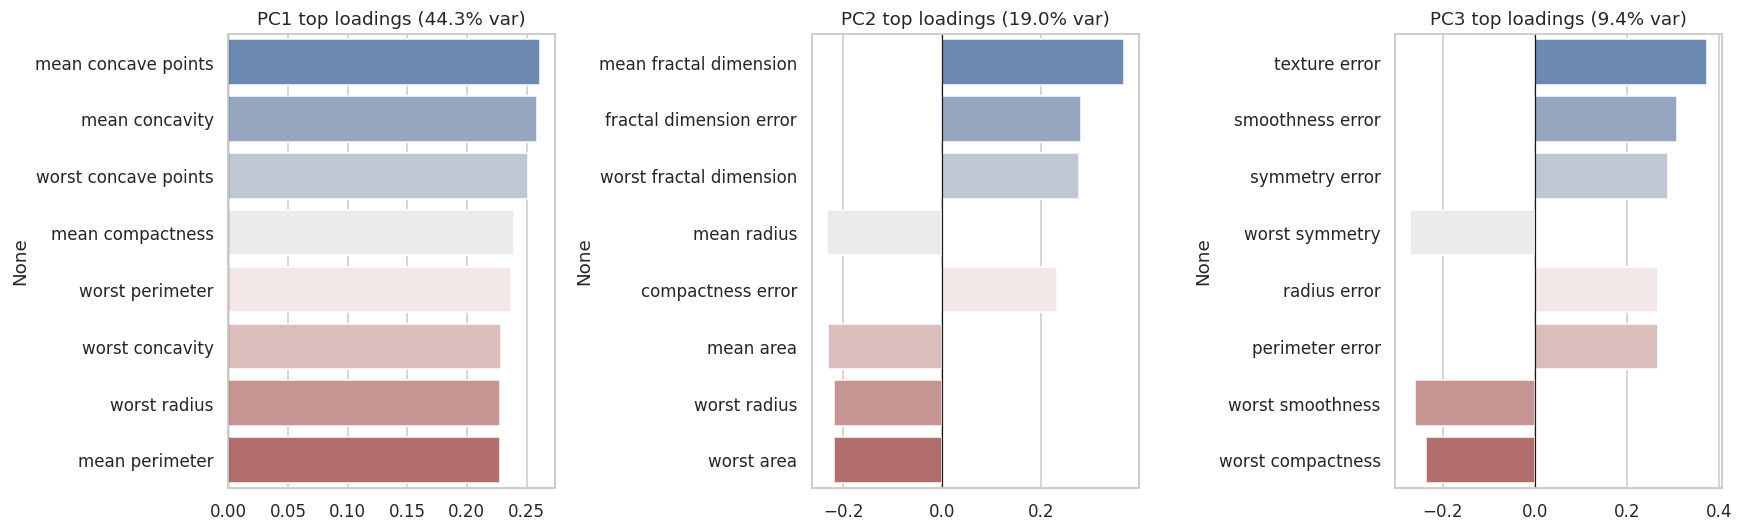

In [6]:
# What do the first components actually represent? Top absolute loadings.
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=pc_cols)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=False)
for ax, pc in zip(axes, ["PC1", "PC2", "PC3"]):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index)[:8]
    sns.barplot(x=top.values, y=top.index, ax=ax, palette="vlag", orient="h")
    ax.set_title(f"{pc} top loadings ({pca.explained_variance_ratio_[int(pc[2:])-1]:.1%} var)")
    ax.axvline(0, c="k", lw=.8)
plt.tight_layout(); plt.show()

PC1 is dominated by size / shape-severity features (radius, perimeter, area, concavity), so it acts as an
overall "tumor magnitude" axis. This is a well-known property of this dataset.

## 3. K-Means: Elbow method and Silhouette analysis

In [7]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X_pca, km.labels_),
        "davies_bouldin": davies_bouldin_score(X_pca, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X_pca, km.labels_),
    })
scores = pd.DataFrame(rows).set_index("k")
display(scores.round(3))

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,10770.290,0.358,1.260,288.125
3,9239.100,0.326,1.457,214.543
4,8450.055,0.286,1.418,173.694
5,7744.447,0.173,1.664,154.735
6,7175.856,0.178,1.639,142.282
7,6742.641,0.169,1.572,131.980
8,6367.784,0.171,1.472,124.290
9,6038.315,0.163,1.431,118.302
10,5827.621,0.163,1.431,111.011


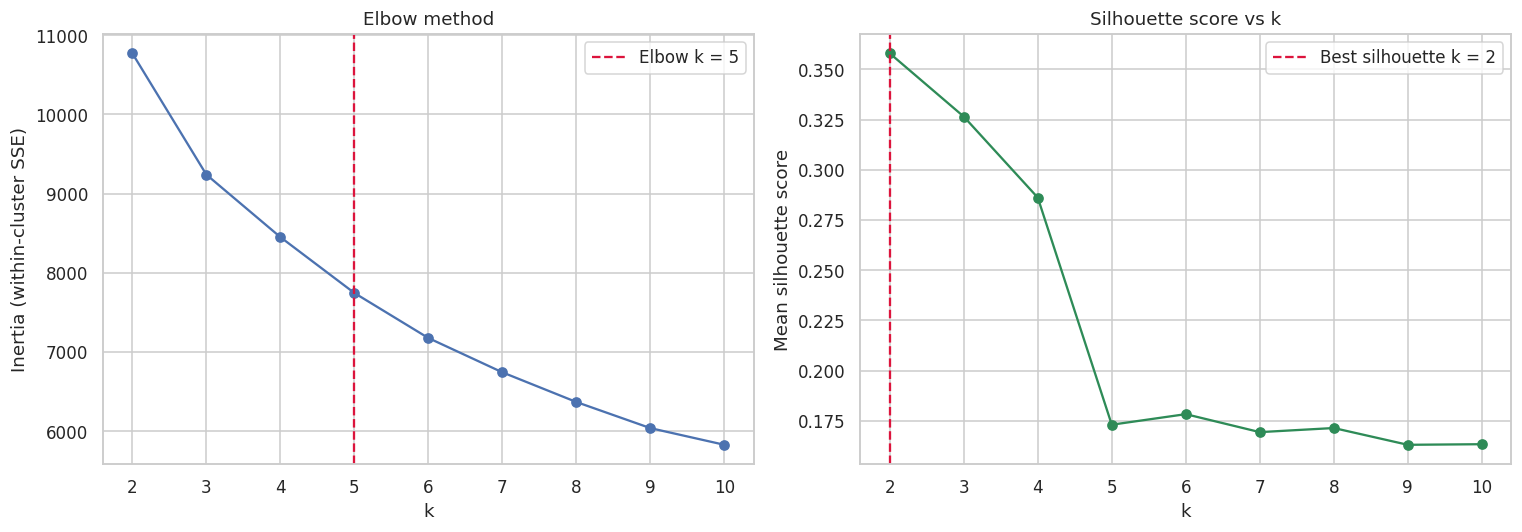

Elbow suggests k = 5; silhouette suggests k = 2


In [8]:
# Programmatic elbow: point of maximum distance from the line joining first and last inertia values
ks = np.array(list(K_RANGE)); inertia = scores["inertia"].values
p1, p2 = np.array([ks[0], inertia[0]]), np.array([ks[-1], inertia[-1]])
d = np.abs(np.cross(p2 - p1, np.column_stack([ks, inertia]) - p1)) / np.linalg.norm(p2 - p1)
k_elbow = int(ks[np.argmax(d)])
k_sil = int(scores["silhouette"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ks, inertia, "o-")
axes[0].axvline(k_elbow, ls="--", c="crimson", label=f"Elbow k = {k_elbow}")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow method"); axes[0].legend()

axes[1].plot(ks, scores["silhouette"], "o-", color="seagreen")
axes[1].axvline(k_sil, ls="--", c="crimson", label=f"Best silhouette k = {k_sil}")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Mean silhouette score")
axes[1].set_title("Silhouette score vs k"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Elbow suggests k = {k_elbow}; silhouette suggests k = {k_sil}")

### Per-sample silhouette plots
The mean score hides detail. Silhouette *plots* show whether each cluster is cohesive and whether any
cluster has many samples below the mean (a sign of a poor split) or negative values (likely misassigned points).

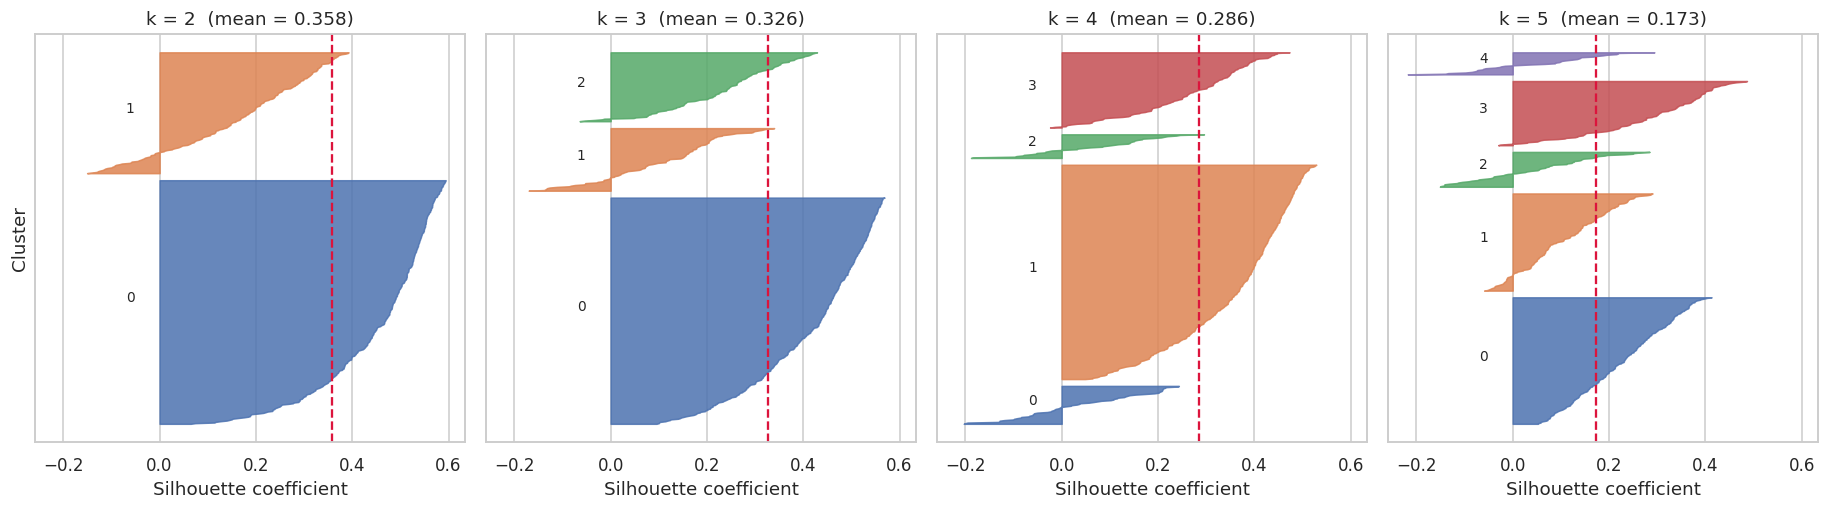

In [9]:
cand_ks = sorted({2, 3, 4, k_elbow, k_sil})
fig, axes = plt.subplots(1, len(cand_ks), figsize=(4.2 * len(cand_ks), 4.8), sharex=True)
axes = np.atleast_1d(axes)

for ax, k in zip(axes, cand_ks):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
    sil = silhouette_samples(X_pca, km.labels_)
    avg = sil.mean()
    y_lo = 10
    for c in range(k):
        s = np.sort(sil[km.labels_ == c])
        ax.fill_betweenx(np.arange(y_lo, y_lo + len(s)), 0, s,
                         color=sns.color_palette("deep")[c % 10], alpha=.85)
        ax.text(-0.07, y_lo + .5 * len(s), str(c), fontsize=9)
        y_lo += len(s) + 10
    ax.axvline(avg, c="crimson", ls="--")
    ax.set_title(f"k = {k}  (mean = {avg:.3f})")
    ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([])
axes[0].set_ylabel("Cluster")
plt.tight_layout(); plt.show()

**Choosing k.** The elbow is often ambiguous, so silhouette is the tie-breaker, and we also sanity-check that
cluster sizes are reasonable. We use the silhouette-optimal *k* below.

In [10]:
K_FINAL = k_sil
km_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=RANDOM_STATE).fit(X_pca)

df = pd.DataFrame(X_pca[:, :3], columns=["PC1", "PC2", "PC3"])
df["KMeans"] = km_final.labels_.astype(str)
df["Diagnosis (held out)"] = y_true.values

print(f"Final K-Means: k = {K_FINAL}, silhouette = {silhouette_score(X_pca, km_final.labels_):.3f}")
print(df["KMeans"].value_counts().sort_index().to_string())

Final K-Means: k = 2, silhouette = 0.358
KMeans
0    380
1    189


## 4. Cluster visualization: 2D (Seaborn) and 3D (Plotly)

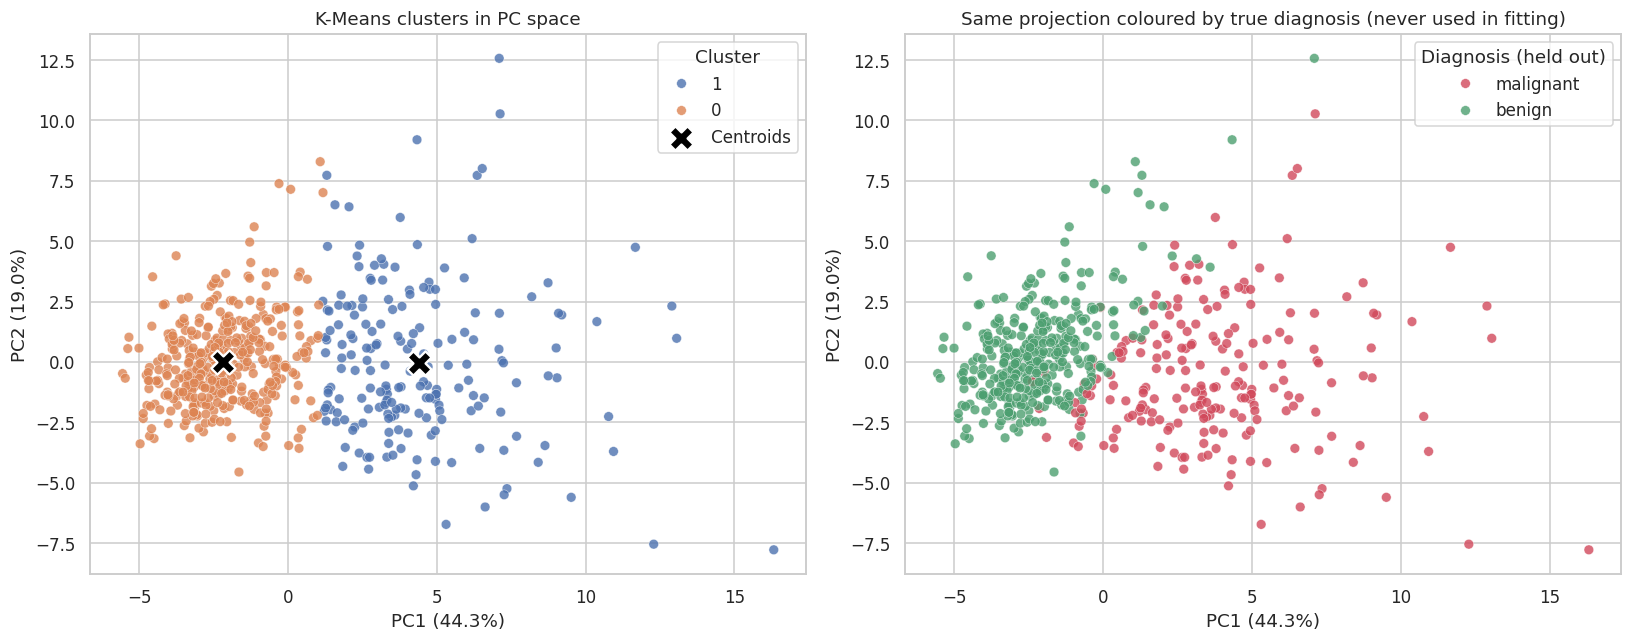

In [11]:
ev = pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df, x="PC1", y="PC2", hue="KMeans", palette="deep",
                s=40, alpha=.8, edgecolor="white", linewidth=.3, ax=axes[0])
cent = km_final.cluster_centers_
axes[0].scatter(cent[:, 0], cent[:, 1], marker="X", s=250, c="black", edgecolor="white", lw=1.5, label="Centroids")
axes[0].set_title("K-Means clusters in PC space")
axes[0].set_xlabel(f"PC1 ({ev[0]:.1%})"); axes[0].set_ylabel(f"PC2 ({ev[1]:.1%})")
axes[0].legend(title="Cluster")

sns.scatterplot(data=df, x="PC1", y="PC2", hue="Diagnosis (held out)",
                palette={"benign": "#4c9f70", "malignant": "#d1495b"},
                s=40, alpha=.8, edgecolor="white", linewidth=.3, ax=axes[1])
axes[1].set_title("Same projection coloured by true diagnosis (never used in fitting)")
axes[1].set_xlabel(f"PC1 ({ev[0]:.1%})"); axes[1].set_ylabel(f"PC2 ({ev[1]:.1%})")
plt.tight_layout(); plt.show()

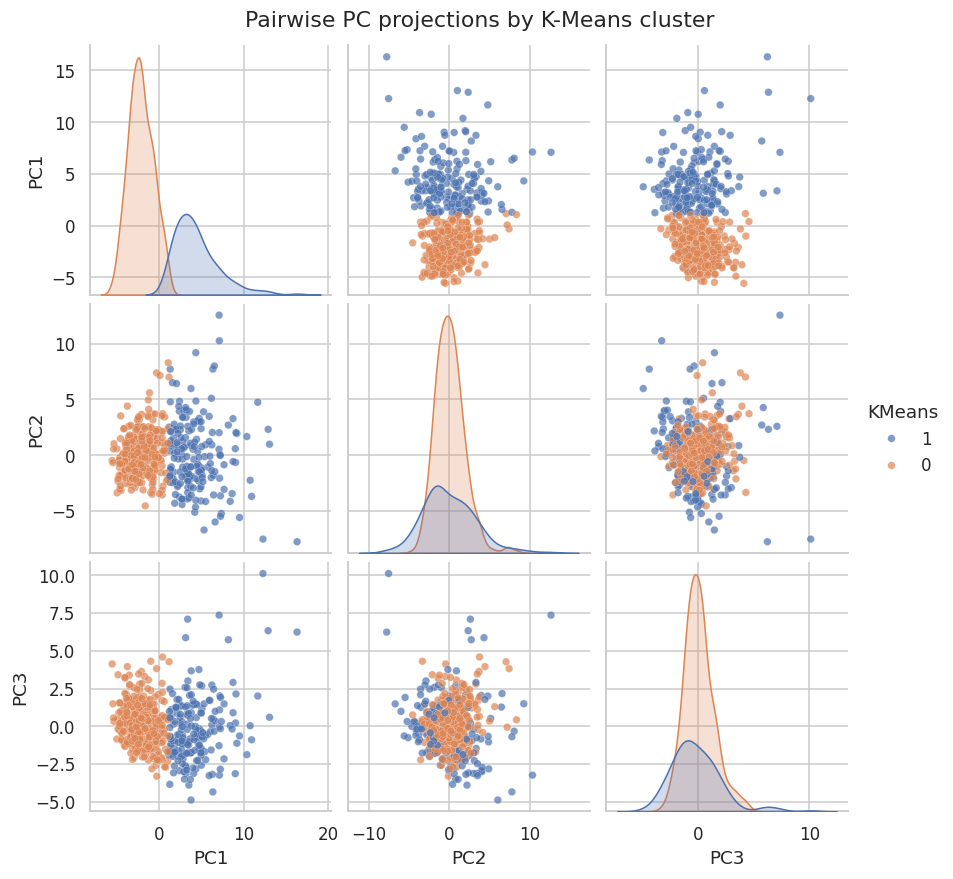

In [12]:
# Pairplot of the first 3 PCs, coloured by cluster
g = sns.pairplot(df, vars=["PC1", "PC2", "PC3"], hue="KMeans", palette="deep",
                 plot_kws=dict(s=25, alpha=.7, edgecolor="white", linewidth=.2),
                 diag_kind="kde", height=2.6)
g.fig.suptitle("Pairwise PC projections by K-Means cluster", y=1.02)
plt.show()

In [13]:
# Interactive 2D
fig = px.scatter(df, x="PC1", y="PC2", color="KMeans", symbol="Diagnosis (held out)",
                 title="Interactive 2D PCA projection (K-Means clusters)",
                 labels={"PC1": f"PC1 ({ev[0]:.1%})", "PC2": f"PC2 ({ev[1]:.1%})"},
                 color_discrete_sequence=px.colors.qualitative.Safe, opacity=.8, height=550)
fig.update_traces(marker=dict(size=7, line=dict(width=.4, color="white")))
fig.show()

In [14]:
# Interactive 3D
fig = px.scatter_3d(df, x="PC1", y="PC2", z="PC3", color="KMeans",
                    hover_data=["Diagnosis (held out)"],
                    title=f"3D PCA projection ({ev[:3].sum():.1%} of variance), K-Means k={K_FINAL}",
                    color_discrete_sequence=px.colors.qualitative.Safe, opacity=.85, height=650)
fig.update_traces(marker=dict(size=4, line=dict(width=.3, color="white")))
fig.update_layout(scene=dict(xaxis_title=f"PC1 ({ev[0]:.1%})",
                             yaxis_title=f"PC2 ({ev[1]:.1%})",
                             zaxis_title=f"PC3 ({ev[2]:.1%})"))
fig.show()

## 5. Hierarchical clustering and DBSCAN
The title calls for three algorithm families, so we also apply Ward-linkage agglomerative clustering
and density-based DBSCAN on the same PCA-reduced data.

### 5a. Hierarchical (Ward linkage)

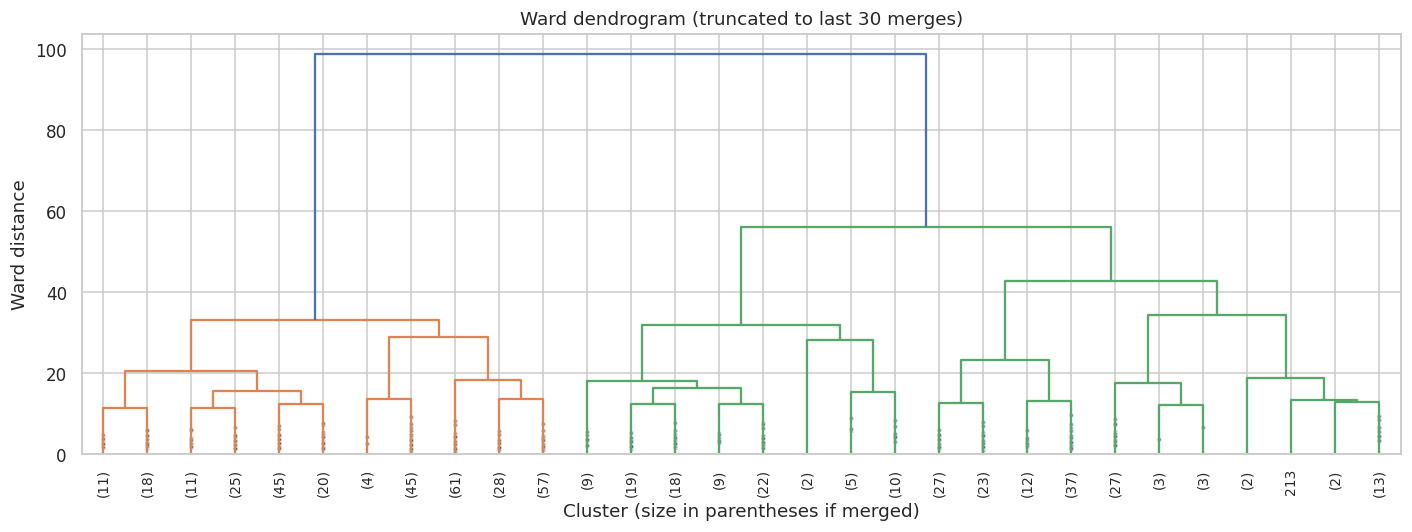

k,2,3,4,5,6,7,8
silhouette,0.296,0.252,0.175,0.18,0.13,0.14,0.139


Hierarchical: best k = 2, silhouette = 0.296


In [15]:
Z = linkage(X_pca, method="ward")

plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=0.7 * Z[-1, 2])
plt.title("Ward dendrogram (truncated to last 30 merges)")
plt.xlabel("Cluster (size in parentheses if merged)"); plt.ylabel("Ward distance")
plt.tight_layout(); plt.show()

hier_scores = {k: silhouette_score(X_pca, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_pca))
               for k in range(2, 9)}
display(pd.Series(hier_scores, name="silhouette").rename_axis("k").round(3).to_frame().T)

K_HIER = max(hier_scores, key=hier_scores.get)
hier_labels = AgglomerativeClustering(n_clusters=K_HIER, linkage="ward").fit_predict(X_pca)
df["Hierarchical"] = hier_labels.astype(str)
print(f"Hierarchical: best k = {K_HIER}, silhouette = {hier_scores[K_HIER]:.3f}")

### 5b. DBSCAN

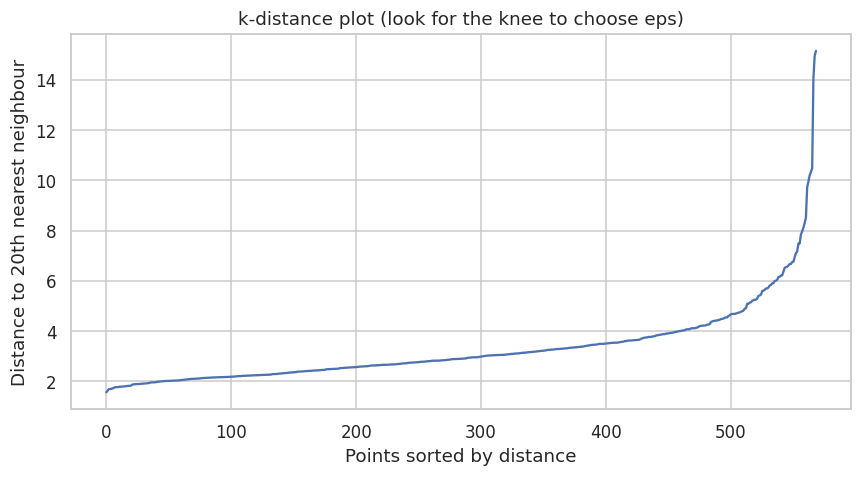

In [16]:
# eps selection via k-distance plot, with min_samples ~ 2 * n_components as a common rule of thumb
MIN_SAMPLES = max(2 * N_COMPONENTS, 5)
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_pca)
kdist = np.sort(nn.kneighbors(X_pca)[0][:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(kdist)
plt.xlabel("Points sorted by distance"); plt.ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
plt.title("k-distance plot (look for the knee to choose eps)")
plt.tight_layout(); plt.show()

In [17]:
# Grid search over eps AND min_samples, scored by silhouette on non-noise points.
# Constraints keep the score meaningful: >= 2 clusters, <= 15% noise (otherwise silhouette is
# inflated simply by throwing awkward points away), and no tiny-fragment solutions (largest cluster >= 50%).
results = []
for ms in (5, 10, MIN_SAMPLES):
    kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X_pca).kneighbors(X_pca)[0][:, -1])
    for eps in np.linspace(np.percentile(kd, 5), np.percentile(kd, 95), 30):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
        mask = lab != -1
        n_cl = len(set(lab[mask]))
        noise = 1 - mask.mean()
        biggest = pd.Series(lab[mask]).value_counts(normalize=True).iloc[0] if n_cl else 0
        sil = silhouette_score(X_pca[mask], lab[mask]) if n_cl >= 2 else np.nan
        results.append(dict(min_samples=ms, eps=eps, n_clusters=n_cl, noise_pct=noise * 100,
                            largest_cluster_share=biggest, silhouette=sil))
grid = pd.DataFrame(results)

print("Distribution of cluster counts across the grid:")
display(grid.groupby("min_samples").n_clusters.value_counts().unstack(fill_value=0))

valid = grid[(grid.n_clusters >= 2) & (grid.noise_pct <= 15) & (grid.largest_cluster_share >= 0.5)].dropna()
best = valid.loc[valid.silhouette.idxmax()] if len(valid) else None
print("\nBest DBSCAN setting under constraints:" if best is not None else
      "\nNo setting produced >= 2 balanced clusters with <= 15% noise.")
if best is not None:
    display(best.to_frame("value").T.round(3))

Distribution of cluster counts across the grid:


n_clusters,1,2,3,4,5,6
min_samples,,,,,,
5,21,3,2,2,1,1
10,27,2,1,0,0,0
20,30,0,0,0,0,0



No setting produced >= 2 balanced clusters with <= 15% noise.


In [18]:
if best is not None:
    EPS, MS = float(best.eps), int(best.min_samples)
else:  # fallback: knee of the k-distance curve; expect a single dominant cluster plus noise
    EPS, MS = float(np.percentile(kdist, 90)), MIN_SAMPLES

db_labels = DBSCAN(eps=EPS, min_samples=MS).fit_predict(X_pca)
df["DBSCAN"] = np.where(db_labels == -1, "noise", db_labels.astype(str))
print(f"DBSCAN eps={EPS:.3f}, min_samples={MS}")
print(df["DBSCAN"].value_counts().to_string())

DBSCAN eps=4.900, min_samples=20
DBSCAN
0        548
noise     21


## 6. Side-by-side comparison

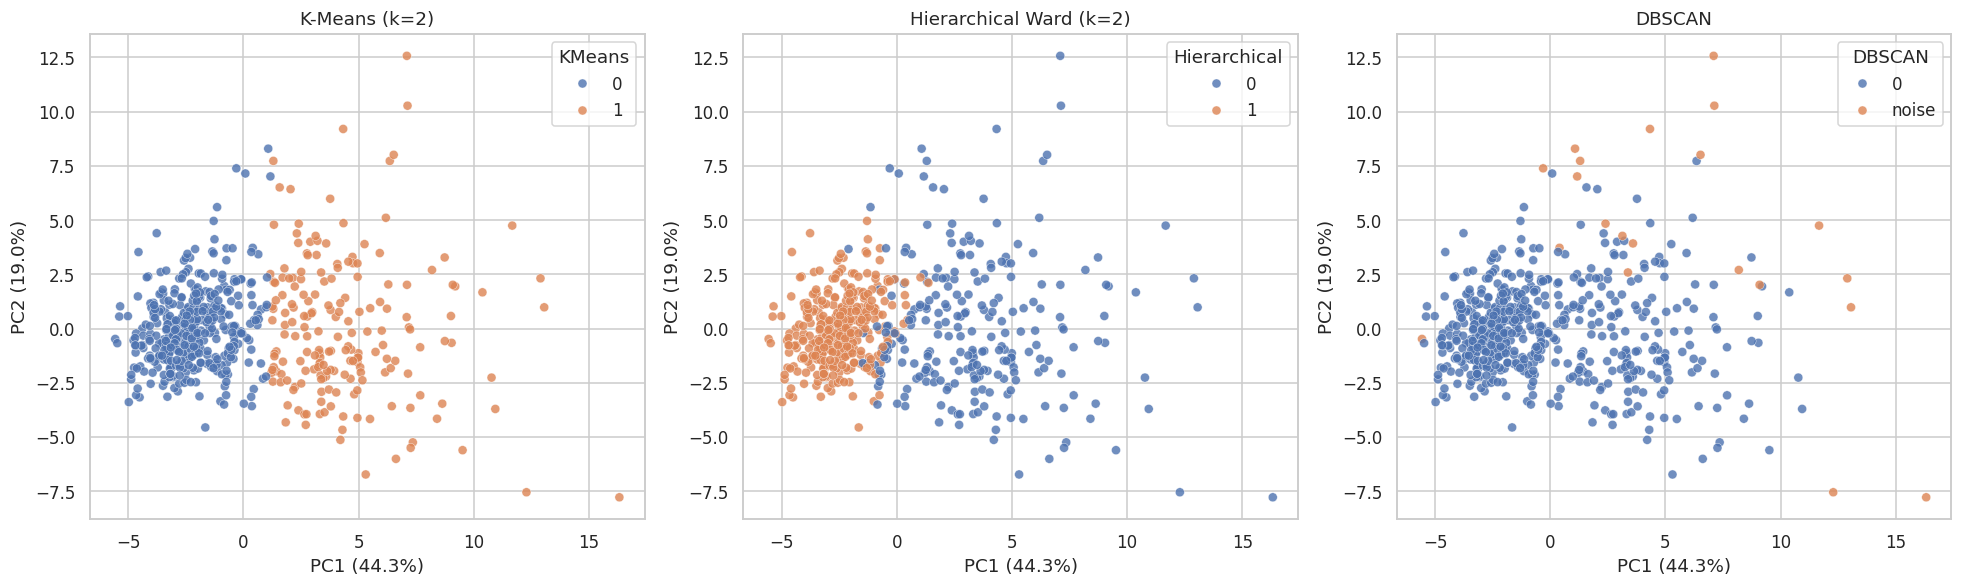

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, col, title in zip(axes, ["KMeans", "Hierarchical", "DBSCAN"],
                          [f"K-Means (k={K_FINAL})", f"Hierarchical Ward (k={K_HIER})", "DBSCAN"]):
    pal = "deep"
    order = sorted(df[col].unique(), key=lambda s: (s == "noise", s))
    sns.scatterplot(data=df, x="PC1", y="PC2", hue=col, hue_order=order, palette=pal,
                    s=35, alpha=.8, edgecolor="white", linewidth=.3, ax=ax)
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({ev[0]:.1%})"); ax.set_ylabel(f"PC2 ({ev[1]:.1%})")
plt.tight_layout(); plt.show()

In [20]:
def evaluate(name, labels):
    labels = np.asarray(labels)
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    out = {"Algorithm": name, "Clusters": n_cl, "Noise %": round(100 * (1 - mask.mean()), 1)}
    if n_cl >= 2:
        out["Silhouette"]        = round(silhouette_score(X_pca[mask], labels[mask]), 3)
        out["Davies-Bouldin (lower=better)"] = round(davies_bouldin_score(X_pca[mask], labels[mask]), 3)
        out["Calinski-Harabasz"] = round(calinski_harabasz_score(X_pca[mask], labels[mask]), 1)
    # External check only; labels were never used for fitting
    out["ARI vs diagnosis"] = round(adjusted_rand_score(y_true[mask], labels[mask]), 3)
    return out

comparison = pd.DataFrame([
    evaluate("K-Means", km_final.labels_),
    evaluate("Hierarchical (Ward)", hier_labels),
    evaluate("DBSCAN", db_labels),
]).set_index("Algorithm")
display(comparison)

,Clusters,Noise %,Silhouette,Davies-Bouldin (lower=better),Calinski-Harabasz,ARI vs diagnosis
Algorithm,,,,,,
K-Means,2,0.0,0.358,1.26,288.1,0.671
Hierarchical (Ward),2,0.0,0.296,1.38,244.1,0.702
DBSCAN,1,3.7,NaN,NaN,NaN,0.000


Diagnosis (held out),benign,malignant,All
KMeans,,,
0,343,37,380
1,14,175,189
All,357,212,569


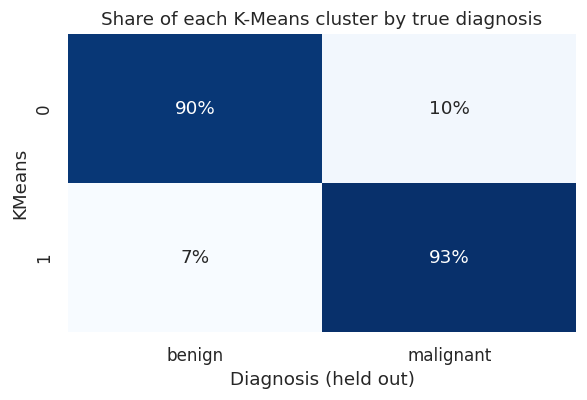

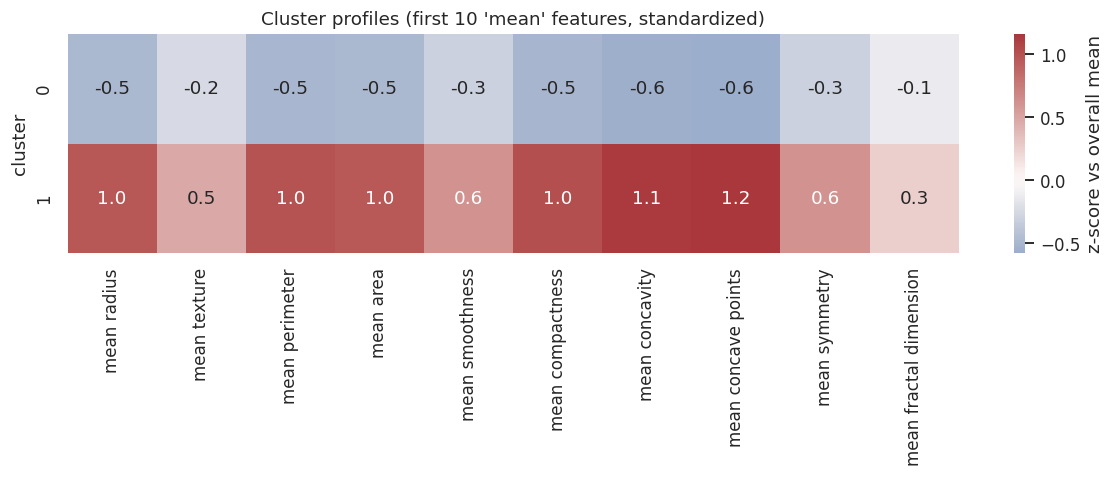

In [21]:
# How do K-Means clusters line up with the true diagnosis?
ct = pd.crosstab(df["KMeans"], df["Diagnosis (held out)"], margins=True)
display(ct)

plt.figure(figsize=(5.5, 3.8))
sns.heatmap(pd.crosstab(df["KMeans"], df["Diagnosis (held out)"], normalize="index"),
            annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Share of each K-Means cluster by true diagnosis"); plt.tight_layout(); plt.show()

# Cluster profiles in original feature units (interpretation)
profile = X.assign(cluster=km_final.labels_).groupby("cluster").mean()
top_feats = X.columns[:10]
plt.figure(figsize=(11, 3.5 + .5 * K_FINAL))
sns.heatmap(((profile - X.mean()) / X.std())[top_feats], annot=True, fmt=".1f",
            cmap="vlag", center=0, cbar_kws={"label": "z-score vs overall mean"})
plt.title("Cluster profiles (first 10 'mean' features, standardized)"); plt.tight_layout(); plt.show()

## 7. Conclusions

**PCA.** The 30 correlated features compress substantially: Kaiser's criterion keeps 6 components, 80% / 90% /
95% of variance needs 5 / 7 / 10 components respectively. We retained **10 components (95.2% variance)** for
clustering, a 3x reduction. PC1 is a "tumor size / severity" axis (radius, perimeter, area, concavity loadings).

**K-Means.** Elbow and silhouette disagree, which is common: the inertia curve has no sharp elbow (our
geometric heuristic picked k=5) while silhouette is highest at **k=2 (0.358)** and falls steadily afterwards
(0.326 at k=3, ~0.17 for k>=5). Davies-Bouldin and Calinski-Harabasz also favour k=2. We therefore used k=2.
The silhouette plots confirm cohesive clusters with only a minority of low-scoring samples.

**Ground-truth check (held out).** K-Means clusters (380 / 189 samples) recover the diagnosis well: 343/380 of
cluster 0 are benign and 175/189 of cluster 1 are malignant (ARI 0.67). Ward hierarchical clustering is
comparable (ARI 0.70) with a lower silhouette (0.296).

**DBSCAN did not work well here, and that is informative.** Searching eps x min_samples, no setting produced
two or more balanced clusters with <= 15% noise. With the best-behaved setting it returns one dominant cluster
plus ~4% noise points (ARI 0). Benign and malignant samples form one *continuous* density region with a
gradual transition, so a density threshold cannot cut between them, whereas centroid / variance-based methods
can. DBSCAN is still useful on this data as an **outlier detector** (the noise points).

| Algorithm | Strengths | Weaknesses observed here |
|---|---|---|
| K-Means | Fast, best silhouette, interpretable centroids | Needs k; elbow ambiguous |
| Hierarchical (Ward) | Dendrogram shows structure; best ARI | O(n^2) memory, no re-assignment |
| DBSCAN | No k needed; flags outliers | Fails on touching clusters of similar density |

**Caveats.** Silhouette is computed in 10-D PCA space; results depend on the retained component count; the
diagnosis labels are only a proxy for "true" structure; cluster ids are arbitrary (compare with ARI).

**Next steps:** UMAP / t-SNE for nonlinear embeddings, Gaussian Mixture Models for soft assignment, HDBSCAN
for variable-density clusters, and bootstrap stability analysis of the chosen k.